<a href="https://colab.research.google.com/github/Dishantchd/DS-practical/blob/main/Ds_practical6/DS_practical_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Teaching Ratings Dataset - Statistical Tests

Q1: T-test    - Does gender affect teaching evaluation scores?

Q2: ANOVA     - Does beauty score differ by age group?

Q3: Chi-square- Is there an association between tenure and gender?

Q4: Correlation - Is evaluation score correlated with beauty score?



In [ ]:
import pandas as pd
from scipy import stats


In [ ]:
df = pd.read_csv("TeachingRatings.csv")
df


,rownames,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof
0,1,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1
1,2,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2
2,3,no,51,male,more,-0.571984,3.7,upper,yes,yes,55,55,3
3,4,no,40,female,more,-0.677963,4.3,upper,yes,yes,40,46,4
4,5,no,31,female,more,1.509794,4.4,upper,yes,yes,42,48,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...
458,459,no,32,male,more,1.231394,3.2,lower,yes,yes,9,21,93
459,460,no,32,male,more,1.231394,4.3,upper,yes,yes,52,86,93
460,461,yes,42,female,more,0.420400,3.3,upper,no,yes,52,67,94
461,462,yes,42,female,more,0.420400,3.2,upper,no,yes,54,66,94


Q1: T-TEST -> Gender vs Evaluation Score"

In [ ]:


male_eval = df[df['gender'] == 'male']['eval']
female_eval = df[df['gender'] == 'female']['eval']

print(f"  Male mean eval    : {male_eval.mean():.4f}  (n={len(male_eval)})")
print(f"  Female mean eval  : {female_eval.mean():.4f}  (n={len(female_eval)})")

t_stat, p_val = stats.ttest_ind(male_eval, female_eval, equal_var=False)
print(f"  t-statistic       : {t_stat:.4f}")
print(f"  p-value           : {p_val:.4f}")

alpha = 0.05
if p_val < alpha:
    print(f"  Decision          : REJECT H0 -> gender DOES affect eval score (p < {alpha})")
else:
    print(f"  Decision          : FAIL TO REJECT H0 -> no significant effect of gender (p >= {alpha})")

  Male mean eval    : 4.0690  (n=268)
  Female mean eval  : 3.9010  (n=195)
  t-statistic       : 3.2667
  p-value           : 0.0012
  Decision          : REJECT H0 -> gender DOES affect eval score (p < 0.05)


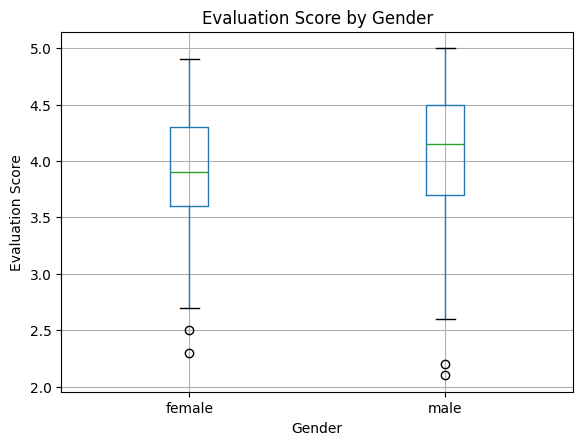

In [ ]:
import matplotlib.pyplot as plt

df.boxplot(column='eval', by='gender')
plt.title("Evaluation Score by Gender")
plt.suptitle('')
plt.xlabel("Gender")
plt.ylabel("Evaluation Score")
plt.show()

In [ ]:
df['age_group'] = pd.qcut(df['age'], q=4,
                           labels=['Young (29-42)', 'Middle (43-48)',
                                   'Upper-Middle (49-57)', 'Senior (58-73)'])

groups = [g['beauty'].values for _, g in df.groupby('age_group')]

print("  Group means:")
for label, g in df.groupby('age_group'):
    print(f"    {label:<22}: mean={g['beauty'].mean():.4f}  (n={len(g)})")

f_stat, p_val2 = stats.f_oneway(*groups)
print(f"  F-statistic       : {f_stat:.4f}")
print(f"  p-value           : {p_val2:.4f}")

if p_val2 < alpha:
    print(f"  Decision          : REJECT H0 -> beauty score DOES differ by age group (p < {alpha})")
else:
    print(f"  Decision          : FAIL TO REJECT H0 -> no significant difference across age groups (p >= {alpha})")

  Group means:
    Young (29-42)         : mean=0.3426  (n=136)
    Middle (43-48)        : mean=-0.1051  (n=97)
    Upper-Middle (49-57)  : mean=-0.1049  (n=136)
    Senior (58-73)        : mean=-0.2354  (n=94)
  F-statistic       : 13.7820
  p-value           : 0.0000
  Decision          : REJECT H0 -> beauty score DOES differ by age group (p < 0.05)


/tmp/ipykernel_1643/2449794814.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  groups = [g['beauty'].values for _, g in df.groupby('age_group')]
/tmp/ipykernel_1643/2449794814.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for label, g in df.groupby('age_group'):


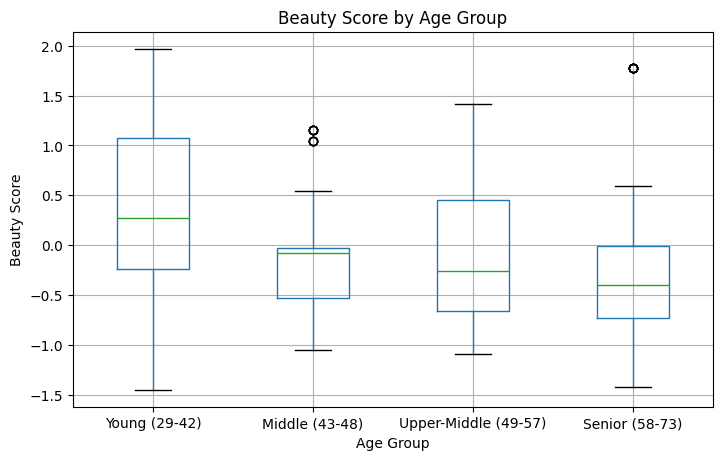

In [ ]:
import matplotlib.pyplot as plt

df.boxplot(column='beauty', by='age_group', figsize=(8,5))
plt.title("Beauty Score by Age Group")
plt.suptitle('')
plt.xlabel("Age Group")
plt.ylabel("Beauty Score")
plt.show()

In [ ]:
contingency = pd.crosstab(df['gender'], df['tenure'])
print("  Contingency table:")
print(contingency.to_string().replace("\n", "\n  "))

chi2, p_val3, dof, expected = stats.chi2_contingency(contingency)
print(f"  Chi-square stat   : {chi2:.4f}")
print(f"  Degrees of freedom: {dof}")
print(f"  p-value           : {p_val3:.4f}")

if p_val3 < alpha:
    print(f"  Decision          : REJECT H0 -> tenure and gender ARE associated (p < {alpha})")
else:
    print(f"  Decision          : FAIL TO REJECT H0 -> no significant association (p >= {alpha})")

  Contingency table:
tenure  no  yes
  gender         
  female  50  145
  male    52  216
  Chi-square stat   : 2.2068
  Degrees of freedom: 1
  p-value           : 0.1374
  Decision          : FAIL TO REJECT H0 -> no significant association (p >= 0.05)


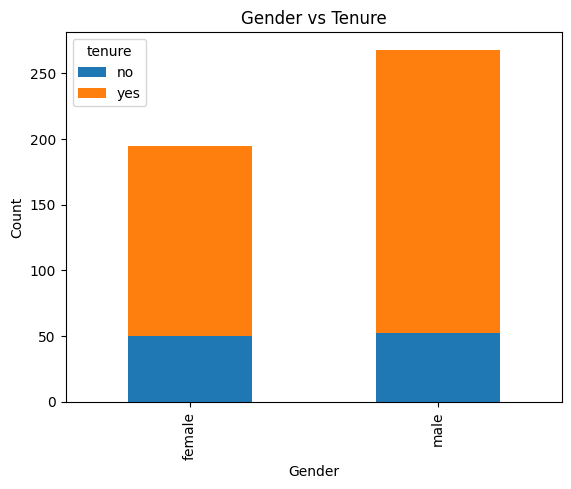

In [ ]:
contingency = pd.crosstab(df['gender'], df['tenure'])

contingency.plot(kind='bar', stacked=True)

plt.title("Gender vs Tenure")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

In [ ]:
r, p_val4 = stats.pearsonr(df['eval'], df['beauty'])
print(f"  Pearson's r       : {r:.4f}")
print(f"  p-value           : {p_val4:.4f}")

if p_val4 < alpha:
    strength = (
        "very weak" if abs(r) < 0.2 else
        "weak" if abs(r) < 0.4 else
        "moderate" if abs(r) < 0.6 else
        "strong"
    )
    direction = "positive" if r > 0 else "negative"
    print(f"  Decision          : REJECT H0 -> significant {strength} {direction} correlation (p < {alpha})")
else:
    print(f"  Decision          : FAIL TO REJECT H0 -> no significant correlation (p >= {alpha})")

  Pearson's r       : 0.1890
  p-value           : 0.0000
  Decision          : REJECT H0 -> significant very weak positive correlation (p < 0.05)


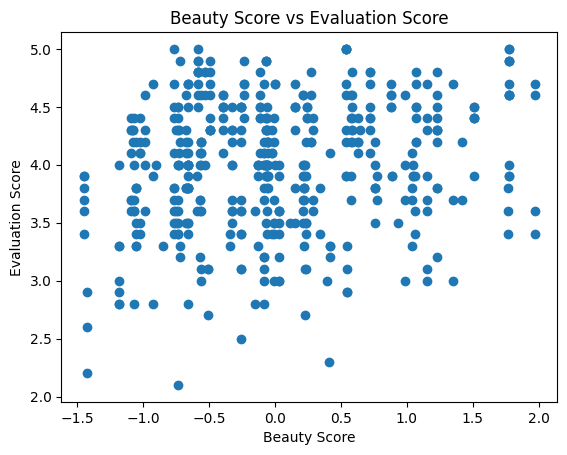

In [ ]:
plt.scatter(df['beauty'], df['eval'])

plt.title("Beauty Score vs Evaluation Score")
plt.xlabel("Beauty Score")
plt.ylabel("Evaluation Score")
plt.show()